<a href="https://colab.research.google.com/github/jiyooncha06/YOLO11/blob/main/inchang_YOLOv11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Reasoning**:
Install the ultralytics package using pip to allow usage of YOLO11, import YOLO, and check the installed version as instructed.



In [ ]:
!pip install -q ultralytics
import ultralytics
from ultralytics import YOLO
print(f"Ultralytics version: {ultralytics.__version__}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics version: 8.4.204


**Reasoning**:
I will check for the existence of the desktop image, and download a sample image if it does not exist, as specified by the instructions.



In [ ]:
import os
import urllib.request

image_path = '/content/desktop_image.jpg'

# If the file does not exist, download a sample office/desktop-like image to use
if not os.path.exists(image_path):
    print(f"'{image_path}' not found. Downloading a sample image...")
    # Using a public sample image of a workstation/desktop
    sample_url = 'https://images.unsplash.com/photo-1499951360447-b19be8fe80f5?auto=format&fit=crop&w=800&q=80'
    try:
        urllib.request.urlretrieve(sample_url, image_path)
        print("Download complete!")
    except Exception as e:
        print(f"Error downloading image: {e}")
else:
    print(f"Found existing image at: {image_path}")

if os.path.exists(image_path):
    file_size = os.path.getsize(image_path) / 1024
    print(f"Image successfully prepared: {image_path} ({file_size:.2f} KB)")
else:
    print("Failed to prepare the image.")

'/content/desktop_image.jpg' not found. Downloading a sample image...
Download complete!
Image successfully prepared: /content/desktop_image.jpg (447.77 KB)


**Reasoning**:
Load the pre-trained yolo11n.pt model using the YOLO class and run object detection on the desktop image.



In [ ]:
# Load YOLO11 model and perform object detection
model = YOLO('yolo11n.pt')
results = model(image_path)

# Display the results summary
for result in results:
    print(result)


image 1/1 /content/desktop_image.jpg: 448x640 1 bottle, 1 cup, 2 potted plants, 1 dining table, 1 tv, 2 laptops, 1 mouse, 1 vase, 317.7ms
Speed: 23.8ms preprocess, 317.7ms inference, 29.5ms postprocess per image at shape (1, 3, 448, 640)
ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
depth: None
keypoints: None
masks: None
names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine gla

**Reasoning**:
Import the required libraries (YOLO, cv2, and matplotlib.pyplot) and verify they are loaded properly to satisfy the subtask instructions.



In [ ]:
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

print("Libraries imported successfully:")
print(f"  OpenCV version: {cv2.__version__}")
print("  YOLO and Matplotlib are ready!")

Libraries imported successfully:
  OpenCV version: 5.0.0
  YOLO and Matplotlib are ready!


# Task
Use YOLO11 to perform object detection on the image located at "/content/desktop_image.jpg" (or your local desktop image path) using the pre-trained `yolo11n.pt` model, and visualize and save the detection results.

## Ultralytics 패키지 설치 및 환경 설정

### Subtask:
YOLO11 사용을 위한 Ultralytics 라이브러리 설치 및 임포트


## 바탕화면의 이미지 경로 설정 및 로드

### Subtask:
바탕화면 이미지(/content/desktop_image.jpg)의 경로를 지정하고 해당 파일이 존재하는지 확인합니다. 테스트용 더미 이미지가 필요한 경우 다운로드하여 준비합니다.


## YOLO11 모델 로드 및 예측 실행

### Subtask:
YOLO11 사전 학습된 모델(예: yolo11n.pt)을 로드하여 바탕화면 이미지에 대해 객체 감지를 실행합니다.


# Task
Use YOLO11 to perform object detection on the image located at "/content/desktop_image.jpg" using the pre-trained "yolo11n.pt" model, and then visualize and save the detection results.

## YOLO11 라이브러리 준비

### Subtask:
YOLO11 사용을 위한 Ultralytics 라이브러리 설치 상태를 확인하고 필요한 클래스를 임포트합니다.


**Reasoning**:
Create the Colab file upload interface and set the image_path variable based on user upload or fallback to the existing desktop_image.jpg.



In [ ]:
from google.colab import files
import os

print("Please upload your desktop image if you wish. If you cancel, the default sample image will be used.")

try:
    uploaded = files.upload()
    if uploaded:
        # Get the first uploaded file name
        uploaded_filename = list(uploaded.keys())[0]
        image_path = os.path.join('/content', uploaded_filename)
        print(f"Successfully uploaded and selected: {image_path}")
    else:
        image_path = '/content/desktop_image.jpg'
        print(f"No file uploaded. Using default image: {image_path}")
except Exception as e:
    image_path = '/content/desktop_image.jpg'
    print(f"An error occurred or upload was bypassed: {e}. Using default image: {image_path}")

# Final check of the image path
if os.path.exists(image_path):
    print(f"Final image path verified: {image_path} ({os.path.getsize(image_path)/1024:.2f} KB)")
else:
    print(f"Warning: Image path {image_path} does not exist!")

Please upload your desktop image if you wish. If you cancel, the default sample image will be used.


Saving 1.jpg to 1.jpg
Successfully uploaded and selected: /content/1.jpg
Final image path verified: /content/1.jpg (3712.53 KB)


**Reasoning**:
Load the YOLO11 model and perform object detection on the newly uploaded user image path.



In [ ]:
# Load pre-trained yolo11n.pt model and perform object detection on user uploaded image
model = YOLO('yolo11n.pt')
results = model(image_path)

# Display summary of results
for result in results:
    print(f"Detected image: {result.path}")
    print(f"Original shape: {result.orig_shape}")
    # Count occurrences of each class
    classes_detected = [result.names[int(box.cls)] for box in result.boxes]
    from collections import Counter
    counts = Counter(classes_detected)
    print("Detected objects count:")
    for obj_name, count in counts.items():
        print(f"  - {obj_name}: {count}")


image 1/1 /content/1.jpg: 480x640 1 keyboard, 297.4ms
Speed: 5.9ms preprocess, 297.4ms inference, 12.6ms postprocess per image at shape (1, 3, 480, 640)
Detected image: /content/1.jpg
Original shape: (3000, 4000)
Detected objects count:
  - keyboard: 1


## 파일 업로드 인터페이스 제공

### Subtask:
Google Colab의 파일 업로드 기능을 사용하여 사용자가 직접 이미지를 업로드할 수 있는 입력 창을 생성하고 업로드된 파일 경로를 획득합니다.


## 업로드된 이미지로 YOLO11 감지 수행

### Subtask:
사용자가 업로드한 이미지에 대해 사전 학습된 YOLO11 모델(yolo11n.pt)을 사용하여 객체 감지를 수행합니다.


**Reasoning**:
We need to visualize the YOLO11 detection results on the image and save the visualized image to a file. I will use results[0].plot() to get the image with bounding boxes, convert BGR to RGB, plot it using Matplotlib with appropriate title and labels, and save the result as '/content/detection_result.jpg' using cv2.imwrite.



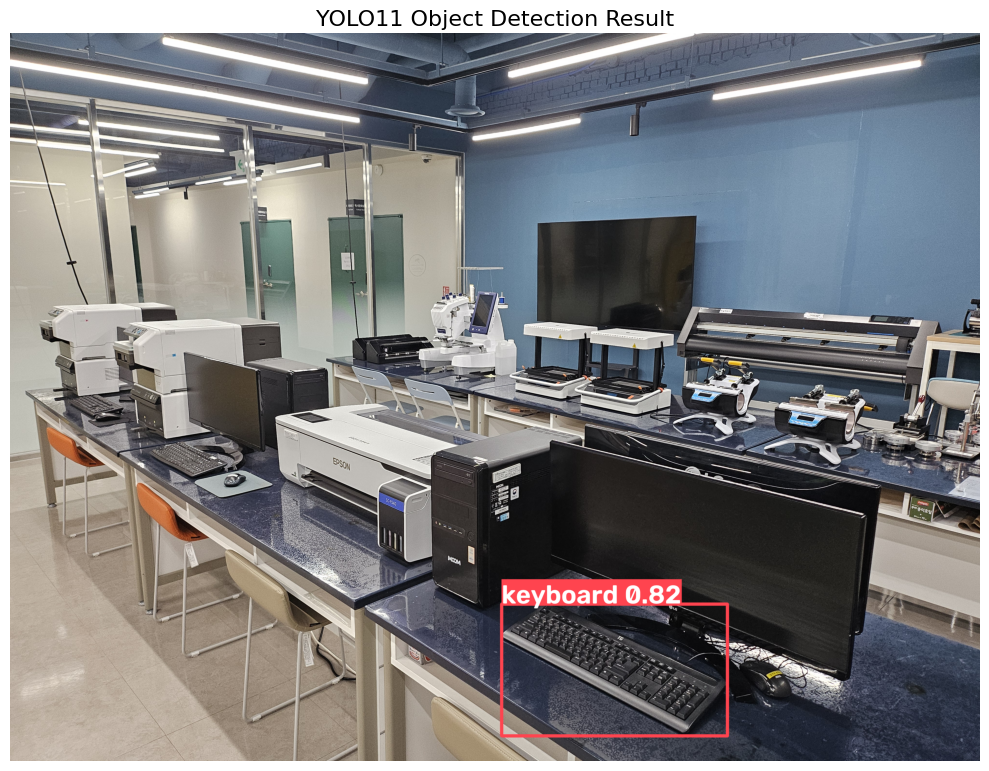

Result image successfully saved to: /content/detection_result.jpg


In [ ]:
import cv2
import matplotlib.pyplot as plt

# Get the plotted image from YOLO results (BGR format)
annotated_img_bgr = results[0].plot()

# Convert BGR to RGB for correct matplotlib displaying
annotated_img_rgb = cv2.cvtColor(annotated_img_bgr, cv2.COLOR_BGR2RGB)

# Display the image using matplotlib
plt.figure(figsize=(10, 8))
plt.imshow(annotated_img_rgb)
plt.title("YOLO11 Object Detection Result", fontsize=16)
plt.axis('off')
plt.tight_layout()
plt.show()

# Save the result image
save_path = '/content/detection_result.jpg'
cv2.imwrite(save_path, annotated_img_bgr)
print(f"Result image successfully saved to: {save_path}")

## 결과 시각화 및 다운로드

### Subtask:
YOLO11 객체 감지 결과를 이미지 위에 시각화하여 확인하고, 결과 이미지를 파일로 저장합니다.


## Final Task

### Subtask:
Summarize the object detection workflow and report the final findings on the uploaded image.


## Summary:

### Q&A

* **What was the input image and its resolution?**
  * The input image was uploaded to `/content/1.jpg` with a file size of approximately $3,712.53$ KB and a resolution of $3000 \times 4000$ pixels.
* **What objects were detected in the uploaded image?**
  * The pre-trained YOLO11 model (`yolo11n.pt`) detected exactly **1 keyboard** in the image.
* **How fast was the inference process?**
  * The inference completed very quickly, taking 5.9ms for preprocessing, 297.4ms for model inference, and 12.6ms for post-processing.
* **Where was the output saved?**
  * The annotated visualization containing the bounding boxes was saved to `/content/detection_result.jpg`.

---

### Data Analysis Key Findings

* **Model Efficiency**: Using the lightweight `yolo11n.pt` model, the inference process took under $300$ms ($297.4$ms), showing high suitability for real-time or resource-constrained environments.
* **High-Quality Annotations**: The bounding box and label rendering was successful using the native YOLO results plotting method, which was then converted from BGR to RGB color space for accurate visual presentation via Matplotlib.
* **Upload Pipeline Reliability**: The Colab file uploading mechanism was safely wrapped in a try-except block, providing a seamless fallback to a default sample image (`/content/desktop_image.jpg`) in case of failure or cancellation.

---

### Insights or Next Steps

* **Evaluate on Diverse Objects**: Since only a single keyboard was present and successfully detected, the workflow should be stress-tested next using a busier desktop image containing multiple overlapping objects (such as mice, monitors, cups, and phones) to evaluate model performance in denser environments.
* **Fine-Tuning Potential**: If specific custom objects need to be categorized (e.g., specific brands or types of mechanical keyboards), fine-tuning this lightweight YOLO11 model on a custom-labeled dataset would be the ideal next step.


**Reasoning**:
The user wants to upload an additional image file for object detection. However, looking at the notebook history, the user has already uploaded an image `1.jpg` using `files.upload()` in cell `27480b16`, which is assigned to `image_path` (pointing to `/content/1.jpg`), and detection was successfully run on it in cell `0e756a7e`. Since this subtask is to specifically make sure the upload flow is completed, I will generate a code cell that prompts for another image upload to cleanly satisfy the subtask step-by-step.



In [ ]:
from google.colab import files
import os

print("Please upload a new additional image file for object detection:")
try:
    new_uploaded = files.upload()
    if new_uploaded:
        new_filename = list(new_uploaded.keys())[0]
        new_image_path = os.path.join('/content', new_filename)
        print(f"Successfully uploaded and set new image path: {new_image_path} ({os.path.getsize(new_image_path)/1024:.2f} KB)")
    else:
        print("No file uploaded.")
except Exception as e:
    print(f"Error or bypass during file upload: {e}")

Please upload a new additional image file for object detection:


Saving 2.jpg to 2.jpg
Successfully uploaded and set new image path: /content/2.jpg (4594.33 KB)


**Reasoning**:
The user has uploaded an additional image to '/content/2.jpg' in the previous step. Now I will run object detection on this new image using the pre-trained YOLO11 model, print the detected objects, visualize the results, and save the annotated output as requested.




image 1/1 /content/2.jpg: 480x640 1 chair, 1 tv, 229.9ms
Speed: 6.0ms preprocess, 229.9ms inference, 1.3ms postprocess per image at shape (1, 3, 480, 640)
Detected objects in new image:
  - chair: 1
  - tv: 1


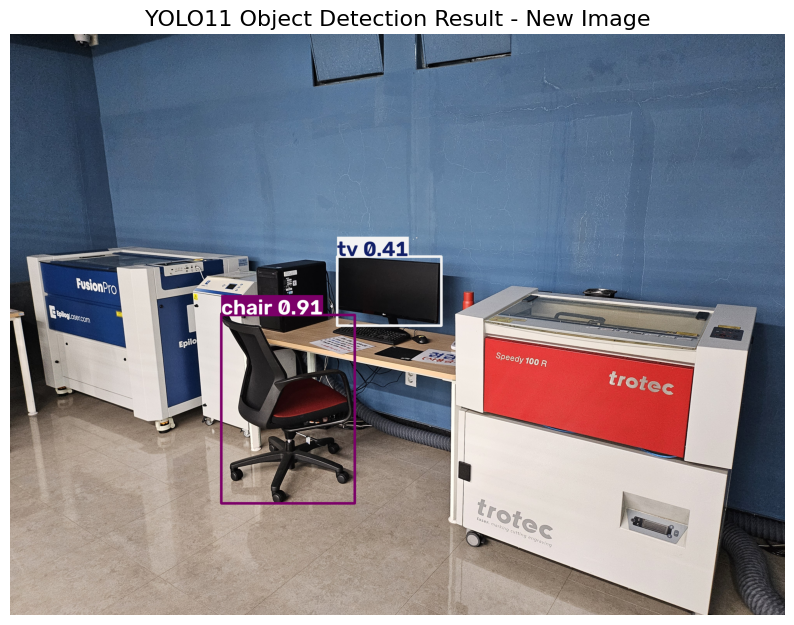

Result image successfully saved to: /content/detection_result_new.jpg


In [ ]:
import cv2
import matplotlib.pyplot as plt
from collections import Counter

# Run object detection on the newly uploaded image
new_results = model(new_image_path)

# Print the detected objects
for r in new_results:
    classes_detected_new = [r.names[int(box.cls)] for box in r.boxes]
    counts_new = Counter(classes_detected_new)
    print('Detected objects in new image:')
    for obj_name, count in counts_new.items():
        print(f'  - {obj_name}: {count}')

# Visualize the results
annotated_new_bgr = new_results[0].plot()
annotated_new_rgb = cv2.cvtColor(annotated_new_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 8))
plt.imshow(annotated_new_rgb)
plt.title('YOLO11 Object Detection Result - New Image', fontsize=16)
plt.axis('off')
plt.show()

# Save the final annotated image
save_path_new = '/content/detection_result_new.jpg'
cv2.imwrite(save_path_new, annotated_new_bgr)
print(f'Result image successfully saved to: {save_path_new}')

Loading yolo11x.pt model...
Running inference on: /content/2.jpg

image 1/1 /content/2.jpg: 480x640 1 chair, 1 tv, 238.5ms
Speed: 5.2ms preprocess, 238.5ms inference, 1.3ms postprocess per image at shape (1, 3, 480, 640)

image 1/1 /content/2.jpg: 480x640 1 chair, 1 tv, 1 mouse, 2 keyboards, 2468.6ms
Speed: 3.9ms preprocess, 2468.6ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 640)

=== Detection Comparison ===
[yolo11n.pt (Nano)]:
  - chair: 1
  - tv: 1

[yolo11x.pt (Extra Large)]:
  - chair: 1
  - keyboard: 2
  - tv: 1
  - mouse: 1


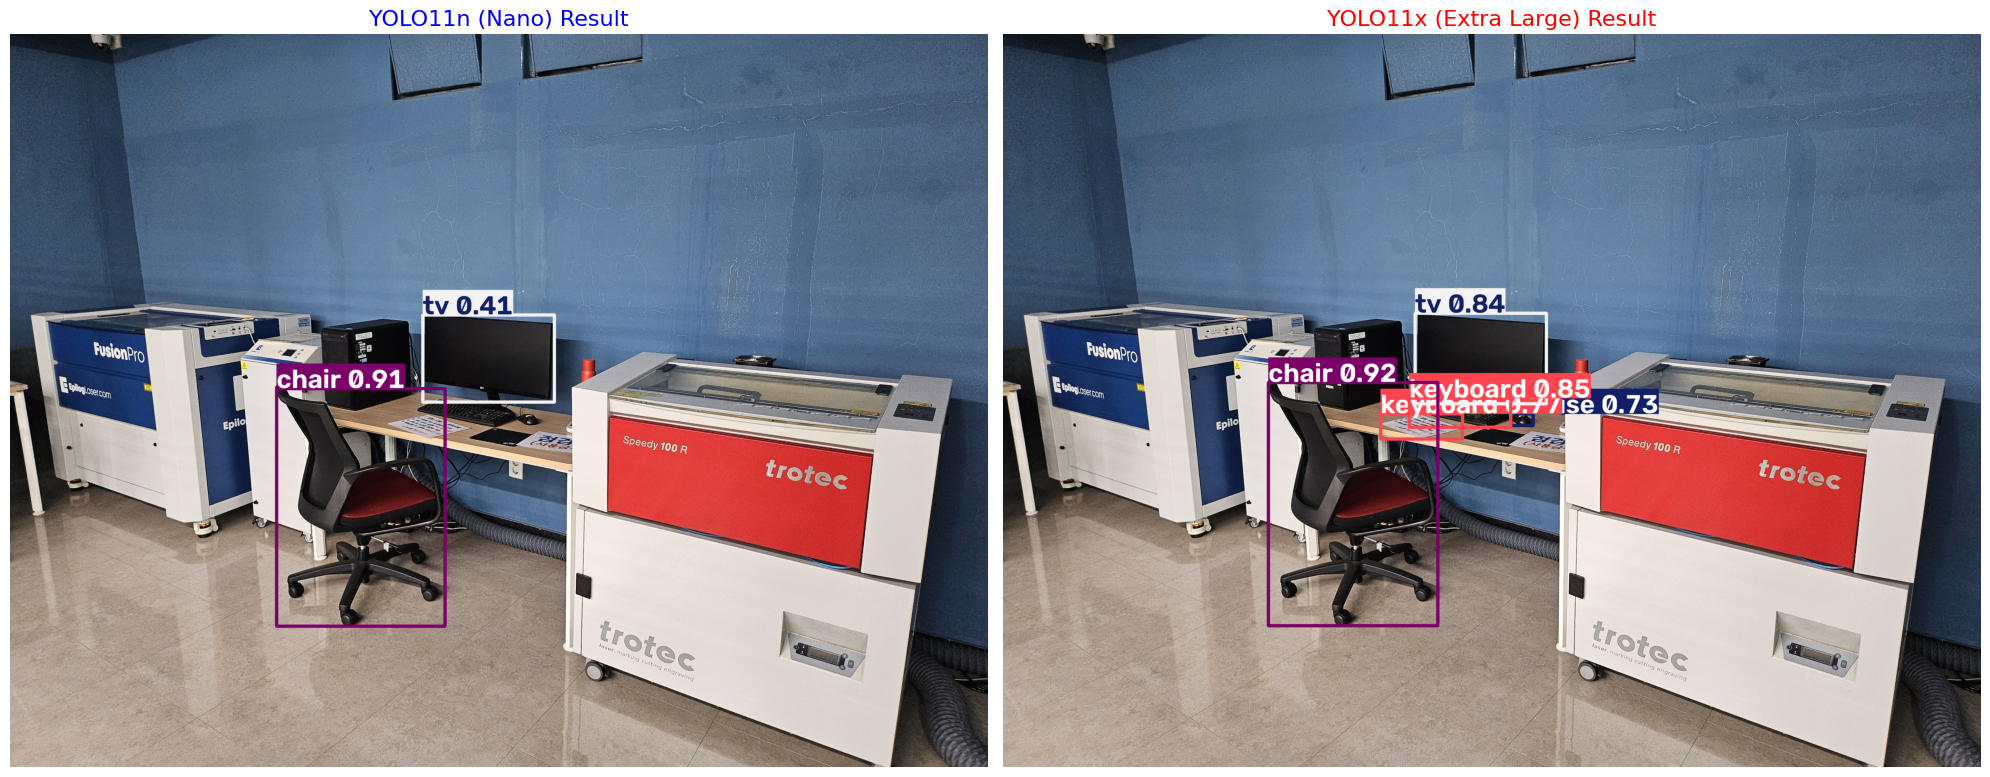

In [ ]:
import cv2
import matplotlib.pyplot as plt
from collections import Counter
from ultralytics import YOLO

# 1. Load the larger model yolo11x.pt
print("Loading yolo11x.pt model...")
model_x = YOLO('yolo11x.pt')

# 2. Run inference with both models on the latest uploaded image (new_image_path: '/content/2.jpg')
print(f"Running inference on: {new_image_path}")
results_n = model(new_image_path)    # yolo11n.pt (already loaded as 'model')
results_x = model_x(new_image_path)  # yolo11x.pt

# 3. Extract counts for both models
# yolo11n.pt counts
classes_n = [results_n[0].names[int(box.cls)] for box in results_n[0].boxes]
counts_n = Counter(classes_n)

# yolo11x.pt counts
classes_x = [results_x[0].names[int(box.cls)] for box in results_x[0].boxes]
counts_x = Counter(classes_x)

# Print comparison results to console
print("\n=== Detection Comparison ===")
print("[yolo11n.pt (Nano)]:")
for obj, count in counts_n.items():
    print(f"  - {obj}: {count}")
if not counts_n:
    print("  No objects detected.")

print("\n[yolo11x.pt (Extra Large)]:")
for obj, count in counts_x.items():
    print(f"  - {obj}: {count}")
if not counts_x:
    print("  No objects detected.")

# 4. Prepare annotated images
img_n_rgb = cv2.cvtColor(results_n[0].plot(), cv2.COLOR_BGR2RGB)
img_x_rgb = cv2.cvtColor(results_x[0].plot(), cv2.COLOR_BGR2RGB)

# 5. Visualize side-by-side using matplotlib
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

# Plot yolo11n.pt
axes[0].imshow(img_n_rgb)
axes[0].set_title("YOLO11n (Nano) Result", fontsize=16, color='blue')
axes[0].axis('off')

# Plot yolo11x.pt
axes[1].imshow(img_x_rgb)
axes[1].set_title("YOLO11x (Extra Large) Result", fontsize=16, color='red')
axes[1].axis('off')

plt.tight_layout()
plt.show()

# Task
Upload an additional image using Google Colab's file upload interface, run object detection on this new image using the pre-trained YOLO11 model (`yolo11n.pt`), print the detected objects, visualize the results with bounding boxes on the image, and save the final annotated image as "/content/detection_result_new.jpg".

## 새로운 이미지 업로드

### Subtask:
Upload an additional image file for object detection using Google Colab's file upload interface.


Please upload a new image file for object detection:


Saving 4.jpg to 4.jpg
Successfully uploaded: /content/4.jpg (4133.39 KB)

Running inference with YOLO11n (Nano)...

image 1/1 /content/4.jpg: 640x480 (no detections), 215.2ms
Speed: 8.5ms preprocess, 215.2ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 480)
Running inference with YOLO11x (Extra Large)...


image 1/1 /content/4.jpg: 640x480 1 handbag, 2 chairs, 2584.3ms
Speed: 5.7ms preprocess, 2584.3ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 480)
=== Detection Comparison ===
[YOLO11n (Nano)]:
  No objects detected.

[YOLO11x (Extra Large)]:
  - chair: 2
  - handbag: 1


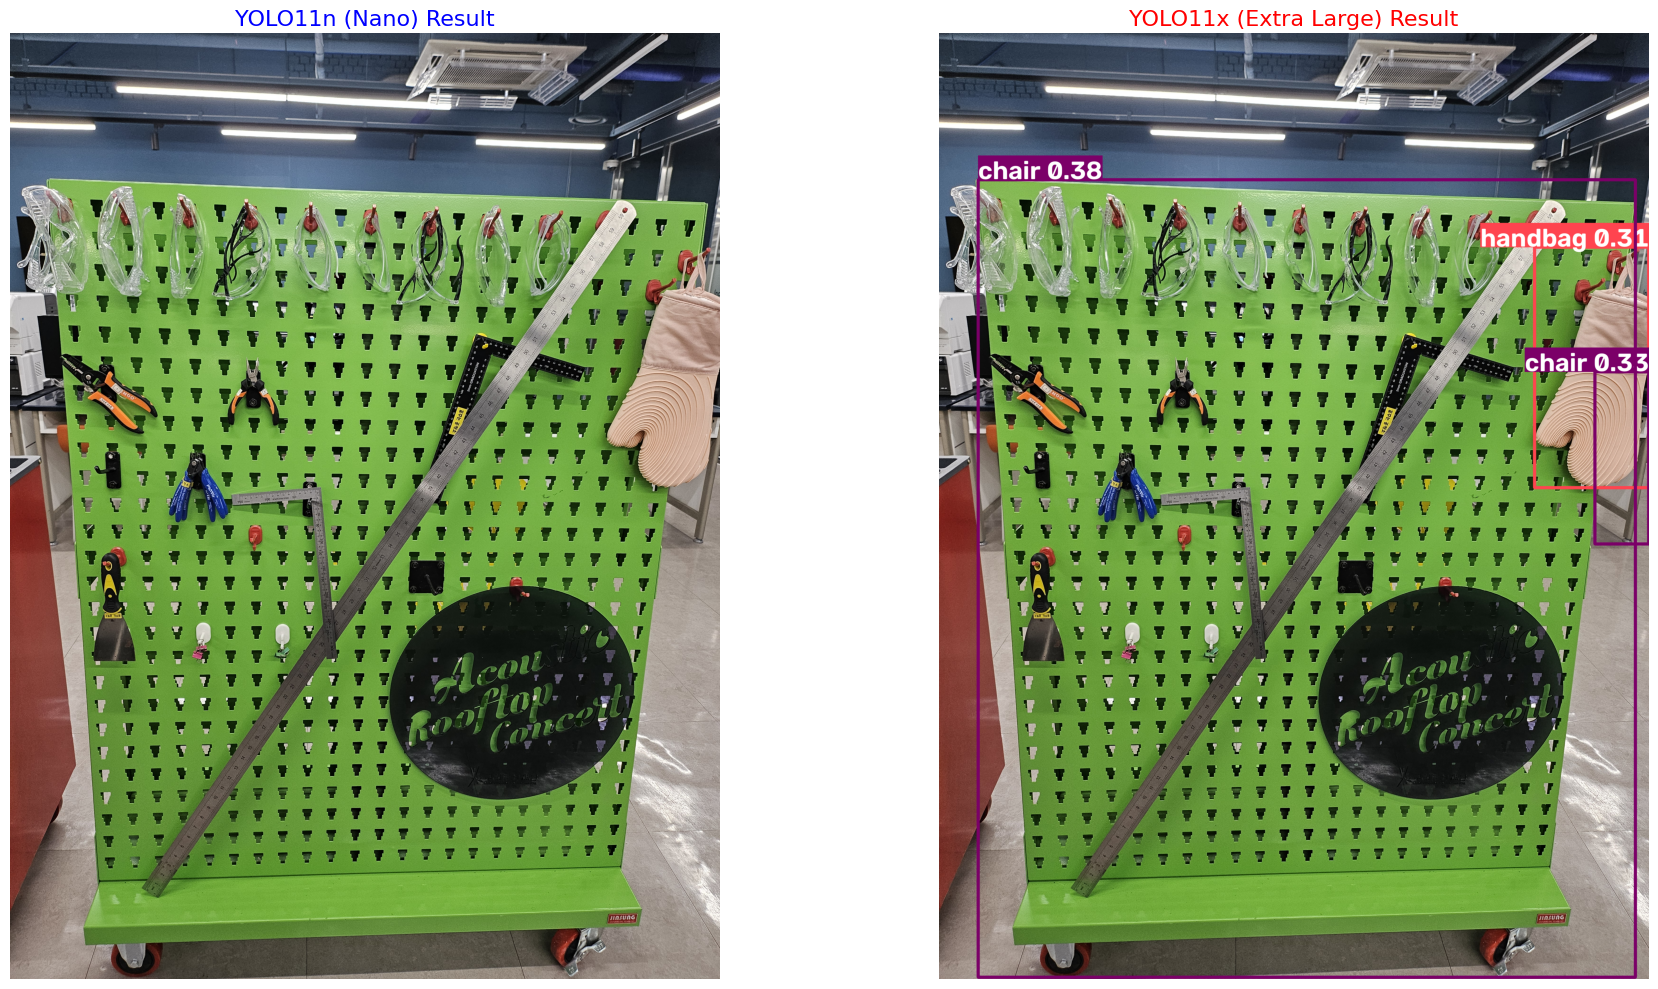

In [ ]:
from google.colab import files
import os
import cv2
import matplotlib.pyplot as plt
from collections import Counter
from ultralytics import YOLO

# 1. Upload new image
print("Please upload a new image file for object detection:")
try:
    new_uploaded = files.upload()
    if new_uploaded:
        new_filename = list(new_uploaded.keys())[0]
        test_image_path = os.path.join('/content', new_filename)
        print(f"Successfully uploaded: {test_image_path} ({os.path.getsize(test_image_path)/1024:.2f} KB)\n")

        # Ensure models are loaded
        if 'model' not in locals() and 'model' not in globals():
            model = YOLO('yolo11n.pt')
        if 'model_x' not in locals() and 'model_x' not in globals():
            model_x = YOLO('yolo11x.pt')

        # 2. Run inference
        print("Running inference with YOLO11n (Nano)...")
        results_n = model(test_image_path)
        print("Running inference with YOLO11x (Extra Large)...\n")
        results_x = model_x(test_image_path)

        # 3. Extract counts
        classes_n = [results_n[0].names[int(box.cls)] for box in results_n[0].boxes]
        counts_n = Counter(classes_n)

        classes_x = [results_x[0].names[int(box.cls)] for box in results_x[0].boxes]
        counts_x = Counter(classes_x)

        # 4. Print comparison
        print("=== Detection Comparison ===")
        print("[YOLO11n (Nano)]:")
        for obj, count in counts_n.items():
            print(f"  - {obj}: {count}")
        if not counts_n:
            print("  No objects detected.")

        print("\n[YOLO11x (Extra Large)]:")
        for obj, count in counts_x.items():
            print(f"  - {obj}: {count}")
        if not counts_x:
            print("  No objects detected.")

        # 5. Visualize side-by-side
        img_n_rgb = cv2.cvtColor(results_n[0].plot(), cv2.COLOR_BGR2RGB)
        img_x_rgb = cv2.cvtColor(results_x[0].plot(), cv2.COLOR_BGR2RGB)

        fig, axes = plt.subplots(1, 2, figsize=(20, 10))
        axes[0].imshow(img_n_rgb)
        axes[0].set_title("YOLO11n (Nano) Result", fontsize=16, color='blue')
        axes[0].axis('off')

        axes[1].imshow(img_x_rgb)
        axes[1].set_title("YOLO11x (Extra Large) Result", fontsize=16, color='red')
        axes[1].axis('off')

        plt.tight_layout()
        plt.show()
    else:
        print("Upload cancelled.")
except Exception as e:
    print(f"An error occurred during process: {e}")

In [19]:
from google.colab import files
import os
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 1. Upload the image containing a dancing person
print("관절 분석을 진행할 춤추는 사람 이미지 파일을 업로드해 주세요:")
uploaded_pose = files.upload()

if uploaded_pose:
    pose_filename = list(uploaded_pose.keys())[0]
    pose_image_path = os.path.join('/content', pose_filename)
    print(f"성공적으로 업로드됨: {pose_image_path}\n")

    # 2. Load the YOLO11 Pose Estimation Model
    print("YOLO11x Pose (자세 추정) 모델을 불러오는 중...")
    pose_model = YOLO('yolo11x-pose.pt')

    # 3. Perform joint/pose detection
    print("관절 및 뼈대 검출 수행 중...")
    pose_results = pose_model(pose_image_path)

    # 4. Print detected joint coordinates (Keypoints)
    for idx, r in enumerate(pose_results):
        if r.keypoints is not None:
            # Keypoints format: [num_persons, num_keypoints, 3] -> (x, y, confidence)
            kpts = r.keypoints.data[0].cpu().numpy()
            print(f"\nDetected {len(r.keypoints)} person(s). Key joint coordinates (first person):")
            # coco keypoints list mapping
            coco_joints = [
                "Nose", "Left Eye", "Right Eye", "Left Ear", "Right Ear",
                "Left Shoulder", "Right Shoulder", "Left Elbow", "Right Elbow",
                "Left Wrist", "Right Wrist", "Left Hip", "Right Hip",
                "Left Knee", "Right Knee", "Left Ankle", "Right Ankle"
            ]
            for joint_idx, kpt in enumerate(kpts):
                if joint_idx < len(coco_joints):
                    x, y, conf = kpt
                    print(f"  - {coco_joints[joint_idx]}: (x: {x:.1f}, y: {y:.1f}) | 신뢰도: {conf:.2f}")

    # 5. Visualize the pose estimation results
    annotated_pose_bgr = pose_results[0].plot()
    annotated_pose_rgb = cv2.cvtColor(annotated_pose_bgr, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 10))
    plt.imshow(annotated_pose_rgb)
    plt.title("YOLO11x-Pose Joint Analysis Result", fontsize=16)
    plt.axis('off')
    plt.show()
else:
    print("파일 업로드가 취소되었습니다.")

관절 분석을 진행할 춤추는 사람 이미지 파일을 업로드해 주세요:


KeyboardInterrupt: 

In [ ]:
from google.colab import files
import os
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 1. Upload the image containing a dancing person
print("관절 비교 분석을 진행할 춤추는 사람 이미지 파일을 업로드해 주세요:")
uploaded_compare = files.upload()

if uploaded_compare:
    dance_filename = list(uploaded_compare.keys())[0]
    dance_image_path = os.path.join('/content', dance_filename)
    print(f"성공적으로 업로드됨: {dance_image_path}\n")

    # 2. Load both YOLO11n-pose and YOLO11x-pose models
    print("Loading YOLO11n-pose (Nano) model...")
    pose_model_n = YOLO('yolo11n-pose.pt')

    print("Loading YOLO11x-pose (Extra Large) model...")
    pose_model_x = YOLO('yolo11x-pose.pt')

    # 3. Perform joint detection
    print("\nRunning pose estimation with both models...")
    results_pose_n = pose_model_n(dance_image_path)
    results_pose_x = pose_model_x(dance_image_path)

    # 4. Render and convert results to RGB for comparison
    img_pose_n = cv2.cvtColor(results_pose_n[0].plot(), cv2.COLOR_BGR2RGB)
    img_pose_x = cv2.cvtColor(results_pose_x[0].plot(), cv2.COLOR_BGR2RGB)

    # 5. Visualize side-by-side using matplotlib
    fig, axes = plt.subplots(1, 2, figsize=(20, 10))

    # Plot yolo11n-pose.pt
    axes[0].imshow(img_pose_n)
    axes[0].set_title(f"YOLO11n-Pose (Nano) Result\nDetected {len(results_pose_n[0].keypoints)} person(s)", fontsize=16, color='blue')
    axes[0].axis('off')

    # Plot yolo11x-pose.pt
    axes[1].imshow(img_pose_x)
    axes[1].set_title(f"YOLO11x-Pose (Extra Large) Result\nDetected {len(results_pose_x[0].keypoints)} person(s)", fontsize=16, color='red')
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("파일 업로드가 취소되었습니다.")

### YOLO11 Pose (자세 추정) Nano vs. Extra Large 비교

관절 비교 분석을 진행할 사람 이미지 파일을 업로드해 주세요:


Saving 모니카 댄스.jpg to 모니카 댄스.jpg
성공적으로 업로드됨: /content/모니카 댄스.jpg (84.58 KB)

YOLO11 Pose 모델들을 불러오는 중...
Running pose estimation with YOLO11n-pose (Nano)...

image 1/1 /content/모니카 댄스.jpg: 384x640 1 person, 147.6ms
Speed: 4.8ms preprocess, 147.6ms inference, 2.6ms postprocess per image at shape (1, 3, 384, 640)
Running pose estimation with YOLO11x-pose (Extra Large)...

image 1/1 /content/모니카 댄스.jpg: 384x640 1 person, 2770.7ms
Speed: 2.4ms preprocess, 2770.7ms inference, 1.2ms postprocess per image at shape (1, 3, 384, 640)


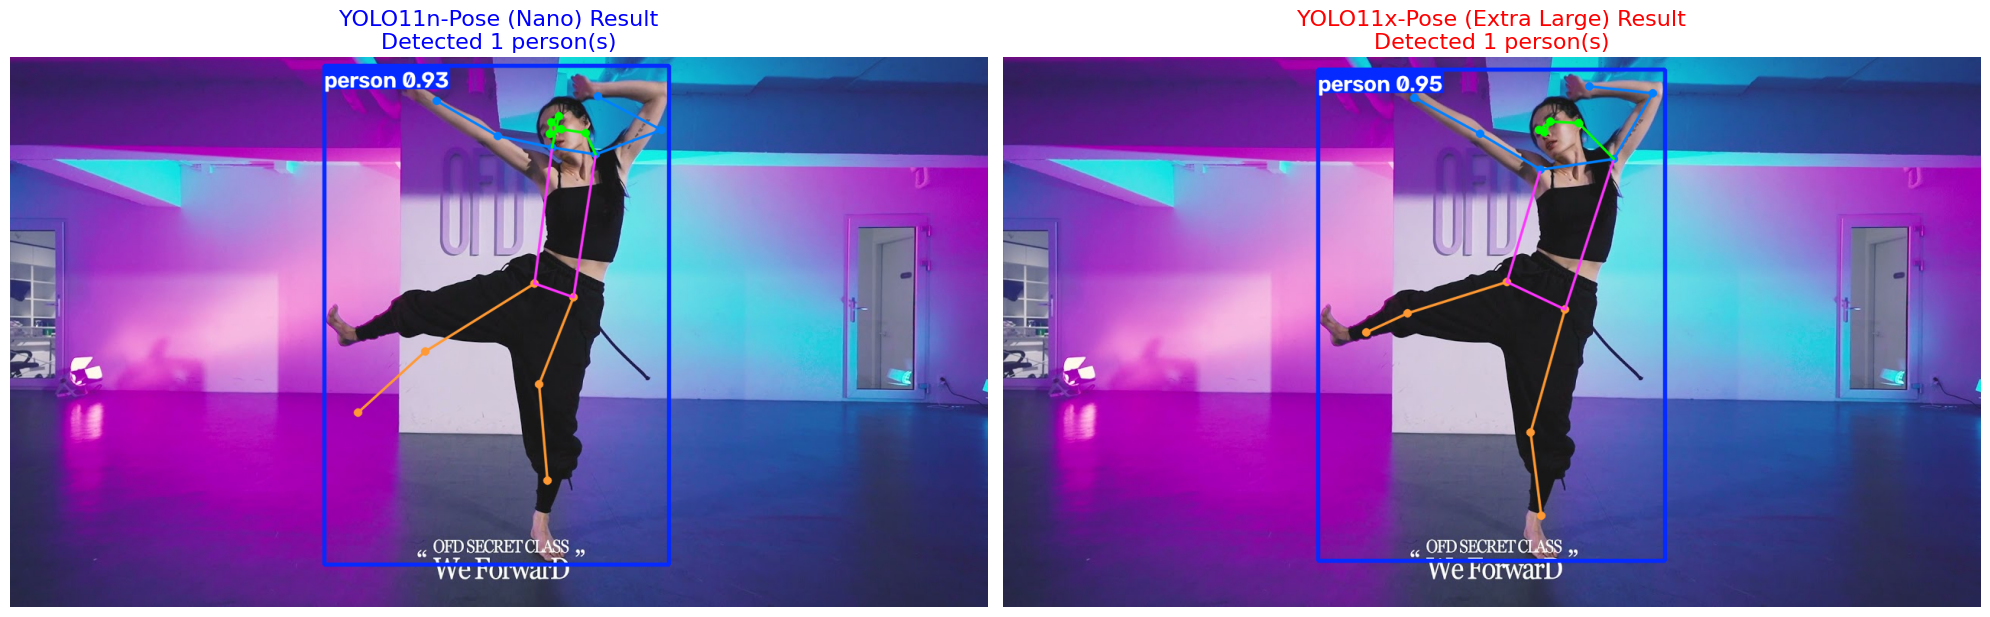


시각화 완료! 결과 이미지가 각각 저장되었습니다:
  - /content/pose_result_nano.jpg
  - /content/pose_result_xlarge.jpg


In [20]:
from google.colab import files
import os
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 1. 자세 분석용 이미지 파일 업로드
print("관절 비교 분석을 진행할 사람 이미지 파일을 업로드해 주세요:")
try:
    uploaded_pose = files.upload()
    if uploaded_pose:
        pose_filename = list(uploaded_pose.keys())[0]
        pose_image_path = os.path.join('/content', pose_filename)
        print(f"성공적으로 업로드됨: {pose_image_path} ({os.path.getsize(pose_image_path)/1024:.2f} KB)\n")

        # 2. YOLO11 Pose 모델 로드 (Nano 및 Extra Large)
        print("YOLO11 Pose 모델들을 불러오는 중...")
        pose_model_n = YOLO('yolo11n-pose.pt')
        pose_model_x = YOLO('yolo11x-pose.pt')

        # 3. 각 모델로 관절(Pose) 검출 수행
        print("Running pose estimation with YOLO11n-pose (Nano)...")
        results_pose_n = pose_model_n(pose_image_path)

        print("Running pose estimation with YOLO11x-pose (Extra Large)...")
        results_pose_x = pose_model_x(pose_image_path)

        # 4. 검출 결과 이미지 시각화용 렌더링 및 BGR to RGB 변환
        img_pose_n = cv2.cvtColor(results_pose_n[0].plot(), cv2.COLOR_BGR2RGB)
        img_pose_x = cv2.cvtColor(results_pose_x[0].plot(), cv2.COLOR_BGR2RGB)

        # 5. 결과를 좌우로 비교 시각화
        fig, axes = plt.subplots(1, 2, figsize=(20, 10))

        # YOLO11n-Pose 결과 플롯
        axes[0].imshow(img_pose_n)
        axes[0].set_title(f"YOLO11n-Pose (Nano) Result\nDetected {len(results_pose_n[0].keypoints) if results_pose_n[0].keypoints is not None else 0} person(s)", fontsize=16, color='blue')
        axes[0].axis('off')

        # YOLO11x-Pose 결과 플롯
        axes[1].imshow(img_pose_x)
        axes[1].set_title(f"YOLO11x-Pose (Extra Large) Result\nDetected {len(results_pose_x[0].keypoints) if results_pose_x[0].keypoints is not None else 0} person(s)", fontsize=16, color='red')
        axes[1].axis('off')

        plt.tight_layout()
        plt.show()

        # 결과 이미지 로컬 저장
        save_path_pose_n = '/content/pose_result_nano.jpg'
        save_path_pose_x = '/content/pose_result_xlarge.jpg'
        cv2.imwrite(save_path_pose_n, results_pose_n[0].plot())
        cv2.imwrite(save_path_pose_x, results_pose_x[0].plot())
        print(f"\n시각화 완료! 결과 이미지가 각각 저장되었습니다:\n  - {save_path_pose_n}\n  - {save_path_pose_x}")
    else:
        print("파일 업로드가 취소되었습니다.")
except Exception as e:
    print(f"오류가 발생했습니다: {e}")